# Random Imputation

- Both on numerical and categorical data

- the distribution will not be altered with this type of imputation.

In [1]:
import numpy as np
import pandas as pd

from sklearn.model_selection import train_test_split

import matplotlib.pyplot as plt
import seaborn as sns

In [7]:
df = pd.read_csv('../../data/train (1).csv',usecols=['Age','Fare','Survived'])

In [8]:
df.head()

,Survived,Age,Fare
0,0,22.0,7.2500
1,1,38.0,71.2833
2,1,26.0,7.9250
3,1,35.0,53.1000
4,0,35.0,8.0500


In [13]:
df.isnull().mean()*100

Survived     0.00000
Age         19.86532
Fare         0.00000
dtype: float64

In [10]:
X = df.drop(columns=['Survived'])
y = df['Survived']

In [11]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [12]:
X_train.head()

,Age,Fare
30,40.0,27.7208
10,4.0,16.7000
873,47.0,9.0000
182,9.0,31.3875
876,20.0,9.8458


In [14]:
X_train['Age_imputed']= X_train['Age']
X_test['Age_imputed']= X_train['Age']

In [15]:
X_train.tail()

,Age,Fare,Age_imputed
534,30.0,8.6625,30.0
584,NaN,8.7125,NaN
493,71.0,49.5042,71.0
527,NaN,221.7792,NaN
168,NaN,25.9250,NaN


In [16]:
X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values
X_test['Age_imputed'][X_test['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_test['Age'].isnull().sum()).values

/var/folders/jb/9m9w0dm52ps6xxz631ss34tm0000gn/T/ipykernel_6706/3090101260.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['Age_imputed'][X_train['Age_imputed'].isnull()] = X_train['Age'].dropna().sample(X_train['Age'].isnull().s

ValueError: cannot set using a list-like indexer with a different length than the value

In [17]:
X_train['Age'].dropna().sample(X_train['Age'].isnull().sum()).values

array([27.  , 64.  , 24.  , 39.  , 50.  , 32.  , 32.5 ,  2.  , 32.  ,
       39.  , 24.  , 25.  , 41.  , 46.  ,  0.42, 34.  , 33.  , 56.  ,
       35.  , 46.  , 24.  , 44.  , 18.  , 21.  , 47.  , 29.  , 28.  ,
       36.  ,  8.  , 56.  , 21.  , 32.  , 29.  , 21.  , 32.  , 44.  ,
       56.  , 21.  , 22.  ,  9.  , 16.  , 49.  , 16.  , 34.  , 26.  ,
       54.  , 30.  , 16.  , 22.  , 19.  , 35.  , 22.  ,  4.  , 32.  ,
       16.  , 14.  , 35.  , 70.  , 21.  , 45.  , 49.  , 36.  , 66.  ,
       29.  , 18.  , 17.  , 20.  ,  4.  , 25.  , 60.  , 23.  , 25.  ,
        9.  , 27.  , 22.  , 40.5 , 36.5 , 34.  , 20.  , 18.  , 25.  ,
       30.  , 39.  , 38.  , 23.  , 58.  , 40.  ,  6.  , 23.  , 45.  ,
       16.  , 18.  , 14.  , 47.  , 22.  , 59.  , 36.  , 17.  , 24.  ,
       58.  , 16.  , 45.  , 40.  , 32.  , 33.  , 21.  , 52.  , 70.5 ,
       45.  , 27.  ,  2.  , 19.  , 18.  , 18.  , 40.  ,  7.  , 40.  ,
       39.  , 24.  , 39.  , 36.  ,  0.83, 28.  , 32.  , 50.  , 45.  ,
       39.  , 24.  ,

In [18]:
X_train['Age'].isnull().sum()

np.int64(148)

In [19]:
X_train

,Age,Fare,Age_imputed
30,40.0,27.7208,40.0
10,4.0,16.7000,4.0
873,47.0,9.0000,47.0
182,9.0,31.3875,9.0
876,20.0,9.8458,20.0
...,...,...,...
534,30.0,8.6625,30.0
584,NaN,8.7125,53.0
493,71.0,49.5042,71.0
527,NaN,221.7792,29.0


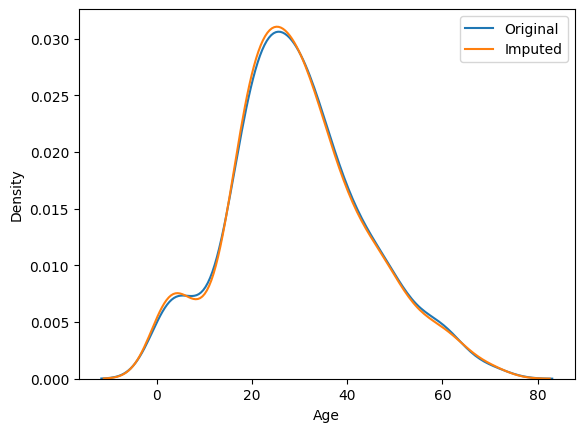

In [20]:
sns.kdeplot(X_train['Age'],label='Original')
sns.kdeplot(X_train['Age_imputed'],label = 'Imputed')

plt.legend()
plt.show()


In [21]:
print('Original variable variance: ', X_train['Age'].var())
print('Variance after random imputation: ', X_train['Age_imputed'].var())

Original variable variance:  204.3495133904614
Variance after random imputation:  205.27500212372897


In [22]:
X_train[['Fare', 'Age', 'Age_imputed']].cov()

,Fare,Age,Age_imputed
Fare,2368.246832,71.512440,47.536193
Age,71.512440,204.349513,204.349513
Age_imputed,47.536193,204.349513,205.275002


<Axes: >

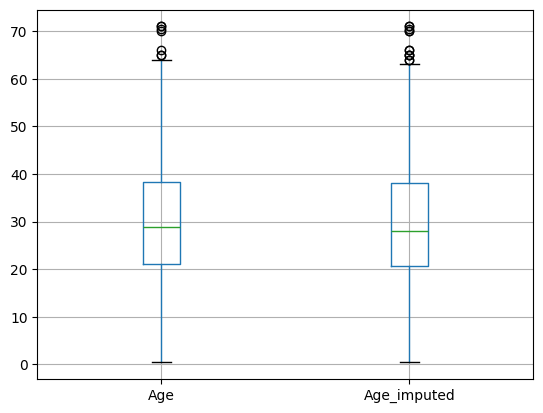

In [23]:
X_train[['Age', 'Age_imputed']].boxplot()

In [26]:
observation = X_train.iloc[0]

sampled_value = X_train['Age'].dropna().sample(
    1,
    random_state=int(observation['Fare'])
)

print(sampled_value)

399    28.0
Name: Age, dtype: float64


# Categorical Data

In [27]:
data = pd.read_csv('../../data/house-train.csv',usecols=['GarageQual','FireplaceQu', 'SalePrice'])

In [28]:
data.head()

,FireplaceQu,GarageQual,SalePrice
0,NaN,TA,208500
1,TA,TA,181500
2,TA,TA,223500
3,Gd,TA,140000
4,TA,TA,250000


In [29]:
data.isnull().mean() * 100

FireplaceQu    47.260274
GarageQual      5.547945
SalePrice       0.000000
dtype: float64

In [31]:
X = data
y = data['SalePrice']

In [32]:
X_train,X_test,y_train,y_test = train_test_split(X,y,test_size=0.2,random_state=2)

In [33]:
X_train['GarageQual_imputed'] = X_train['GarageQual']
X_test['GarageQual_imputed'] = X_test['GarageQual']

X_train['FireplaceQu_imputed'] = X_train['FireplaceQu']
X_test['FireplaceQu_imputed'] = X_test['FireplaceQu']

In [34]:
X_train.sample(5)

,FireplaceQu,GarageQual,SalePrice,GarageQual_imputed,FireplaceQu_imputed
1351,Gd,TA,171000,TA,Gd
583,Gd,Gd,325000,Gd,Gd
114,TA,TA,259500,TA,TA
1284,Gd,TA,169000,TA,Gd
37,TA,TA,153000,TA,TA


In [35]:
X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_train['GarageQual'].isnull().sum()).values
X_test['GarageQual_imputed'][X_test['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_test['GarageQual'].isnull().sum()).values

X_train['FireplaceQu_imputed'][X_train['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_train['FireplaceQu'].isnull().sum()).values
X_test['FireplaceQu_imputed'][X_test['FireplaceQu_imputed'].isnull()] = X_train['FireplaceQu'].dropna().sample(X_test['FireplaceQu'].isnull().sum()).values

/var/folders/jb/9m9w0dm52ps6xxz631ss34tm0000gn/T/ipykernel_6706/856878696.py:1: FutureWarning: ChainedAssignmentError: behaviour will change in pandas 3.0!
You are setting values through chained assignment. Currently this works in certain cases, but when using Copy-on-Write (which will become the default behaviour in pandas 3.0) this will never work to update the original DataFrame or Series, because the intermediate object on which we are setting values will behave as a copy.
A typical example is when you are setting values in a column of a DataFrame, like:

df["col"][row_indexer] = value

Use `df.loc[row_indexer, "col"] = values` instead, to perform the assignment in a single step and ensure this keeps updating the original `df`.

See the caveats in the documentation: https://pandas.pydata.org/pandas-docs/stable/user_guide/indexing.html#returning-a-view-versus-a-copy

  X_train['GarageQual_imputed'][X_train['GarageQual_imputed'].isnull()] = X_train['GarageQual'].dropna().sample(X_tra

In [36]:
temp = pd.concat(
        [
            X_train['GarageQual'].value_counts() / len(X_train['GarageQual'].dropna()),
            X_train['GarageQual_imputed'].value_counts() / len(X_train)
        ],
        axis=1)

temp.columns = ['original', 'imputed']


In [37]:
temp

,original,imputed
TA,0.951043,0.948630
Fa,0.037171,0.038527
Gd,0.009973,0.011130
Po,0.000907,0.000856
Ex,0.000907,0.000856


In [38]:
temp = pd.concat(
        [
            X_train['FireplaceQu'].value_counts() / len(X_train['FireplaceQu'].dropna()),
            X_train['FireplaceQu_imputed'].value_counts() / len(df)
        ],
        axis=1)

temp.columns = ['original', 'imputed']

temp

,original,imputed
Gd,0.494272,0.649832
TA,0.412439,0.542088
Fa,0.040917,0.050505
Po,0.027823,0.035915
Ex,0.024550,0.032548


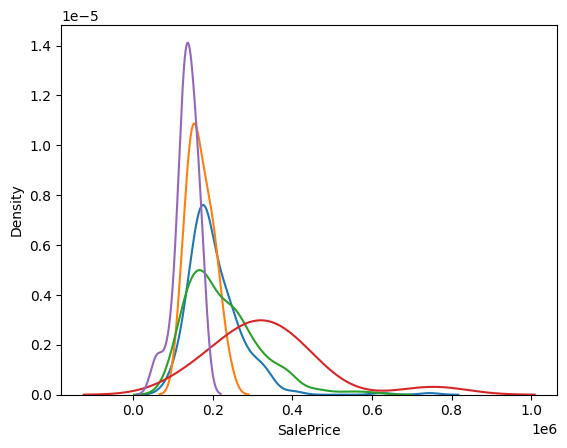

In [40]:
for category in X_train['FireplaceQu'].dropna().unique():
    sns.kdeplot(X_train[X_train['FireplaceQu'] == category]['SalePrice'],label=category)
plt.show()